<a href="https://colab.research.google.com/github/sidcodes2727/ML-labs/blob/main/MLlab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("shalmamuji/electricity-cost-prediction-dataset")
path

Using Colab cache for faster access to the 'electricity-cost-prediction-dataset' dataset.


'/kaggle/input/electricity-cost-prediction-dataset'

In [ ]:
import pandas as pd
df = pd.read_csv("/kaggle/input/electricity-cost-prediction-dataset/electricity_cost_dataset.csv")
print(df.columns)
print(df.duplicated().sum())
print(df.isnull().sum())
df

Index(['site area', 'structure type', 'water consumption', 'recycling rate',
       'utilisation rate', 'air qality index', 'issue reolution time',
       'resident count', 'electricity cost'],
      dtype='object')
0
site area               0
structure type          0
water consumption       0
recycling rate          0
utilisation rate        0
air qality index        0
issue reolution time    0
resident count          0
electricity cost        0
dtype: int64


,site area,structure type,water consumption,recycling rate,utilisation rate,air qality index,issue reolution time,resident count,electricity cost
0,1360,Mixed-use,2519.0,69,52,188,1,72,1420.0
1,4272,Mixed-use,2324.0,50,76,165,65,261,3298.0
2,3592,Mixed-use,2701.0,20,94,198,39,117,3115.0
3,966,Residential,1000.0,13,60,74,3,35,1575.0
4,4926,Residential,5990.0,23,65,32,57,185,4301.0
...,...,...,...,...,...,...,...,...,...
9995,708,Commercial,1365.0,76,77,22,23,0,885.0
9996,2960,Residential,3332.0,22,72,100,47,54,3081.0
9997,3942,Commercial,2427.0,61,43,48,49,0,3325.0
9998,3211,Commercial,4639.0,72,73,105,55,0,2892.0


In [ ]:
from sklearn.preprocessing import OneHotEncoder
enc= OneHotEncoder()
enc_df= pd.DataFrame(enc.fit_transform(df[['structure type']]).toarray(),columns=['struc1','struc2','struc3','struc4'])
df= df.drop(columns=['structure type'])
df= df.join(enc_df)
df

,site area,water consumption,recycling rate,utilisation rate,air qality index,issue reolution time,resident count,electricity cost,struc1,struc2,struc3,struc4
0,1360,2519.0,69,52,188,1,72,1420.0,0.0,0.0,1.0,0.0
1,4272,2324.0,50,76,165,65,261,3298.0,0.0,0.0,1.0,0.0
2,3592,2701.0,20,94,198,39,117,3115.0,0.0,0.0,1.0,0.0
3,966,1000.0,13,60,74,3,35,1575.0,0.0,0.0,0.0,1.0
4,4926,5990.0,23,65,32,57,185,4301.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,708,1365.0,76,77,22,23,0,885.0,1.0,0.0,0.0,0.0
9996,2960,3332.0,22,72,100,47,54,3081.0,0.0,0.0,0.0,1.0
9997,3942,2427.0,61,43,48,49,0,3325.0,1.0,0.0,0.0,0.0
9998,3211,4639.0,72,73,105,55,0,2892.0,1.0,0.0,0.0,0.0


In [ ]:
X = df.drop(columns=['electricity cost'])
y = df['electricity cost']

print(X.shape)
print(y.shape)

(10000, 11)
(10000,)


In [ ]:
from sklearn.model_selection import train_test_split
X=df.drop(columns=['electricity cost'])
y=df['electricity cost']
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(7000, 11)
(3000, 11)
(7000,)
(3000,)


In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [ ]:
w= np.zeros(X_train_scaled.shape[1])
b= 0
lr= 0.01
epochs= 1000
error= []

In [ ]:
for i in range(epochs):
    yp=np.dot(X_train_scaled, w)+b
    e=yp-y_train
    mse=np.mean(e**2)
    error.append(mse)

    dw= (2/len(X_train_scaled))*np.dot(X_train_scaled.T, e)
    db= (2/len(X_train_scaled))*np.sum(e)

    w=w- lr*dw
    b=b- lr*db
print(error)
print("Weights:\n", w)
print("Bias:\n", b)
print("Final Error:\n", error[-1])

[np.float64(9324962.749142857), np.float64(8930901.7640472), np.float64(8554781.56726736), np.float64(8195705.884859322), np.float64(7852828.917719995), np.float64(7525352.114917236), np.float64(7212521.176825019), np.float64(6913623.270391651), np.float64(6627984.440295071), np.float64(6354967.20104699), np.float64(6093968.296307015), np.float64(5844416.6127678165), np.float64(5605771.236981573), np.float64(5377519.644423752), np.float64(5159176.010939893), np.float64(4950279.637500744), np.float64(4750393.479906933), np.float64(4559102.775741458), np.float64(4376013.761471669), np.float64(4200752.473156683), np.float64(4032963.62472522), np.float64(3872309.558256617), np.float64(3718469.261127629), np.float64(3571137.445282721), np.float64(3430023.6842488004), np.float64(3294851.6038493826), np.float64(3165358.122880369), np.float64(3041292.740292312), np.float64(2922416.8656841093), np.float64(2808503.190152468), np.float64(2699335.094761907), np.float64(2594706.0941030383), np.floa

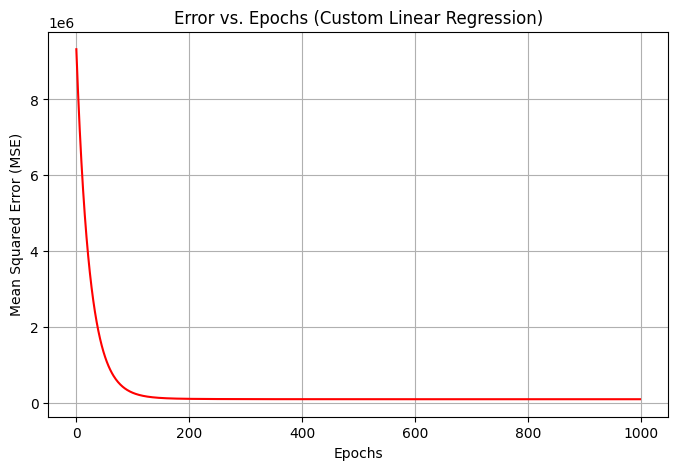

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(epochs), error, color='red')
plt.title('Error vs. Epochs (Custom Linear Regression)')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error

y_pred_custom= np.dot(X_test_scaled,w)+b
custom_mse= np.mean((y_pred_custom-y_test)**2)

custom_mse=mean_squared_error(y_test,y_pred_custom)

print(f"Custom Linear Regression Test MSE: {custom_mse:.2f}")

Custom Linear Regression Test MSE: 95475.20


In [ ]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()
model.fit(X_train,y_train)
y_pred= model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error
mse= mean_squared_error(y_test, y_pred)
rmse= np.sqrt(mse)
print("Linear regression library:")
print(f"MSE  : {mse:.2f}")

Linear regression library:
MSE  : 95432.78
